# 04 | Controlled Segmentation Evaluation
**Evaluating Underwater Image Enhancement for CNN-Based Robotic Segmentation**

This experiment evaluates whether CLAHE and pretrained FUnIE-GAN alter the segmentation accuracy of the same U-Net trained exclusively on RAW SUIM images. I compare the three input conditions on identical official test images, with unchanged annotations, preprocessing conventions, model weights, and evaluation procedures. The results therefore describe **inference-time enhancement of a RAW-trained model**, not the potential performance of models retrained on enhanced data.


## 1. Introduction, Research Question, and Hypotheses

Underwater image enhancement may increase visual contrast or alter color distributions, but changes that appear beneficial to a human observer need not help a semantic segmentation network. Notebook 03 established that CLAHE substantially increased gradient magnitude and luminance variation, whereas FUnIE-GAN reduced the fraction of near-extreme channel values. Neither finding established an improvement in downstream perception.

I therefore evaluate the research question: **Does applying CLAHE or FUnIE-GAN to underwater test images improve segmentation by an unchanged U-Net trained on RAW images?** The comparison is paired by image identity and examines overall mean Intersection over Union (mIoU), pixel accuracy, per-class IoU, plant and robot detection, prediction errors, and processing time. My initial hypothesis was that enhancement might help visually challenging categories; the alternative possibility was that enhancement would shift the input distribution away from the one learned during training. The experiment tests these possibilities without changing the model or tuning on the test set.


## 2. Experimental Environment and Reproducibility


In [1]:
import os
import sys
import json
import time
import random
import hashlib
import shutil
import zipfile
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from google.colab import drive

drive.mount('/content/drive')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
ROOT = Path('/content/drive/MyDrive/Underwater_Research')
PROJECT = Path('/content/suim_project')
SOURCE = PROJECT / 'src'
MANIFEST = PROJECT / 'results/tables/notebook_01/manifest.csv'
CHECKPOINT = ROOT / 'checkpoints/notebook_02_public_research_v1/final/best.pth'
ENHANCED = ROOT / 'results/enhanced'
NB03 = ROOT / 'results/tables/notebook_03'
OUT = ROOT / 'results/tables/notebook_04'
FIG = ROOT / 'results/figures/notebook_04'
PRED = ROOT / 'results/predictions/notebook_04'
for folder in [OUT, FIG, PRED]: folder.mkdir(parents=True, exist_ok=True)
archive = ROOT / 'underwater-robotic-segmentation.zip'
assert archive.is_file() and (ROOT/'manifest.csv').is_file() and (ROOT/'exclusions.csv').is_file()
if not (PROJECT/'data/SUIM').is_dir() or not (SOURCE/'dataset.py').is_file():
    with zipfile.ZipFile(archive) as z:
        matches = [name for name in z.namelist() if name.endswith('src/train.py')]
        assert len(matches) == 1
        prefix = matches[0][:-len('src/train.py')]
        for member in z.infolist():
            if member.is_dir() or not member.filename.startswith(prefix): continue
            rel = Path(member.filename[len(prefix):])
            if not rel.parts or '..' in rel.parts or rel.parts[0] not in {'src','data'}: continue
            dst = PROJECT/rel
            dst.parent.mkdir(parents=True, exist_ok=True)
            with z.open(member) as src, dst.open('wb') as target: shutil.copyfileobj(src,target)
SOURCE.mkdir(parents=True,exist_ok=True)
for filename in ['common.py','dataset.py','unet.py','train.py','build_manifest.py']:
    src = ROOT/'source_review'/filename
    assert src.is_file(), f'Missing reviewed source {src}'
    shutil.copy2(src, SOURCE/filename)
MANIFEST.parent.mkdir(parents=True,exist_ok=True)
shutil.copy2(ROOT/'manifest.csv',MANIFEST)
shutil.copy2(ROOT/'exclusions.csv',MANIFEST.parent/'exclusions.csv')
os.chdir(PROJECT)
if str(SOURCE) not in sys.path: sys.path.insert(0,str(SOURCE))
from dataset import SuimDataset
from common import CLASS_NAMES, NUM_CLASSES
from unet import SmallUNet
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180})
print('Device:',DEVICE,'| Python:',platform.python_version(),'| Torch:',torch.__version__)
print('Research folder:',ROOT)

Mounted at /content/drive
Device: cpu | Python: 3.13.18 | Torch: 2.14.1+cpu
Research folder: /content/drive/MyDrive/Underwater_Research


## 3. Locked Dataset Integrity and Ground-Truth Verification

I verified the Notebook 01 manifest using its SHA-256 checksum and confirmed the original partitions of 1,204 training, 214 validation, and **110 official test images**. The test dataset was loaded without augmentation. Image dimensions, eight-class mask labels, and test-image ordering were checked before evaluation. The integrity check passed, confirming that the comparison used the same 110 test images and unchanged ground-truth masks across conditions. No validation images entered the test evaluation.


In [ ]:
EXPECTED_SHA = '30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69'
manifest_sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
assert manifest_sha == EXPECTED_SHA
manifest_df = pd.read_csv(MANIFEST)
assert manifest_df['stem'].is_unique
assert manifest_df['split'].value_counts().to_dict() == {'train':1204,'val':214,'test':110}
assert len(pd.read_csv(MANIFEST.parent/'exclusions.csv')) == 107
test_ds = SuimDataset('test',manifest=MANIFEST,augment=False)
STEMS = manifest_df.loc[manifest_df['split']=='test','stem'].astype(str).tolist()
assert len(test_ds) == len(STEMS) == 110
assert list(map(str,test_ds.stems)) == STEMS
assert len(CLASS_NAMES) == NUM_CLASSES == 8
assert list(CLASS_NAMES) == ['water','diver','plant','wreck','robot','reef','fish','sea-floor']
for i in range(len(test_ds)):
    x,y = test_ds[i]
    assert x.shape == (3,256,256) and y.shape == (256,256)
    assert y.min() >= 0 and y.max() < NUM_CLASSES
print('Locked dataset verified: 110 official test images; masks unchanged.')

Locked dataset verified: 110 official test images; masks unchanged.


## 4. Frozen Baseline U-Net Checkpoint

I restored the best U-Net checkpoint selected in Notebook 02 at **epoch 112**, using strict state-dictionary loading to detect architectural mismatches. The checkpoint SHA-256 was recorded as `2244ff0337185bfba8d2621e7541bd373bfc7af0f0331af32155b46e51d466f`. I set the network to evaluation mode and disabled gradients for every parameter. Consequently, differences between conditions cannot be attributed to retraining or checkpoint selection.

The previously reported **42.00% validation mIoU** was a model-selection result; it is not substituted for the official test metrics reported below.


In [ ]:
assert CHECKPOINT.is_file(), f'Missing checkpoint: {CHECKPOINT}'
checkpoint_sha = hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest()
ckpt = torch.load(CHECKPOINT,map_location='cpu',weights_only=False)
assert isinstance(ckpt,dict) and 'model' in ckpt and 'config' in ckpt
assert ckpt['config'].get('manifest') == str(MANIFEST), 'Checkpoint manifest path differs from Notebook 02.'
summary_path = CHECKPOINT.parent/'best_validation.json'
assert summary_path.is_file(), 'Missing Notebook 02 validation selection record.'
selection_summary = json.loads(summary_path.read_text())
assert int(selection_summary['best_epoch']) == 112, 'Expected epoch-112 model.'
model = SmallUNet(num_classes=NUM_CLASSES,base=16).to(DEVICE)
model.load_state_dict(ckpt['model'],strict=True)
model.eval()
for parameter in model.parameters(): parameter.requires_grad_(False)
assert not model.training and all(not p.requires_grad for p in model.parameters())
print('Frozen model loaded | best epoch:',selection_summary['best_epoch'])
print('Checkpoint SHA256:',checkpoint_sha)

Frozen model loaded | best epoch: 112
Checkpoint SHA256: 2244ff0337185bfba8d2621e7541bd373bfc7af0f0331af32155b464e51d466f


## 5. Matched Inputs and Enhancement Integrity

I matched CLAHE and FUnIE-GAN PNGs to RAW test images using their unique image stems, rather than relying on file-system order. The verification confirmed **110 complete matched triplets** and validated the SHA-256 records for **220 enhanced test PNGs**. All conditions used the Notebook 02 normalization convention, converting RGB pixel values to the network's expected numerical range. The original test masks were used for every condition. These checks isolate image enhancement as the principal manipulated input factor.


In [ ]:
config_path = NB03/'enhancement_config.json'
enhancement_manifest_path = NB03/'enhancement_manifest.csv'
assert config_path.is_file() and enhancement_manifest_path.is_file()
locked_config = json.loads(config_path.read_text())
assert locked_config['manifest_sha256'] == EXPECTED_SHA
assert locked_config['image_size'] == [256,256]
assert locked_config['clahe'] == {'clip_limit':2.0,'tile_grid':8}
enh_manifest = pd.read_csv(enhancement_manifest_path)
assert len(enh_manifest) == 648
assert not enh_manifest.duplicated(['split','stem','method']).any()
assert enh_manifest.groupby(['split','method']).size().to_dict() == {
    ('val','clahe'):214,('val','funie_gan'):214,
    ('test','clahe'):110,('test','funie_gan'):110}
METHODS = ['raw','clahe','funie_gan']
LABELS = {'raw':'RAW','clahe':'CLAHE','funie_gan':'FUnIE-GAN'}
COLORS = {'raw':'#64748B','clahe':'#16A34A','funie_gan':'#8B5CF6'}
file_index = {}
for row in enh_manifest.loc[enh_manifest['split']=='test'].itertuples(index=False):
    expected = ENHANCED/row.method/'test'/f'{row.stem}.png'
    assert expected.is_file(), f'Missing: {expected}'
    assert hashlib.sha256(expected.read_bytes()).hexdigest() == row.sha256, f'Hash mismatch: {expected}'
    file_index[(str(row.stem),row.method)] = expected
assert len(file_index) == 220

def load_input(stem,method,index):
    if method == 'raw':
        x,_ = test_ds[index]
        return x
    with Image.open(file_index[(stem,method)]) as image:
        assert image.mode == 'RGB' and image.size == (256,256)
        rgb = np.asarray(image).copy()
    assert rgb.dtype == np.uint8 and rgb.shape == (256,256,3)
    return torch.from_numpy(rgb).permute(2,0,1).float()/127.5-1

def input_rgb(stem,method,index):
    x = load_input(stem,method,index)
    return np.clip(np.rint((x.permute(1,2,0).numpy()+1)*127.5),0,255).astype(np.uint8)

for i,stem in enumerate(STEMS):
    for method in METHODS: assert load_input(stem,method,i).shape == (3,256,256)
print('Verified 110 matched RAW triplets and 220 enhanced test PNG hashes.')

Verified 110 matched RAW triplets and 220 enhanced test PNG hashes.


## 6. Controlled Inference and Prediction Preservation

I applied the same frozen U-Net independently to RAW, CLAHE, and FUnIE-GAN inputs for all 110 official test images. The run completed all image triplets and saved **330 lossless class-index prediction masks**. I also preserved per-image confusion counts so that comparisons could be reconstructed without rerunning the model. The execution produced a Pillow `mode` deprecation warning during mask saving; this did not prevent completion or invalidate the saved masks.


In [ ]:
def confusion_counts(gt,pred):
    assert gt.shape == pred.shape == (256,256)
    assert np.min(gt)>=0 and np.max(gt)<NUM_CLASSES
    assert np.min(pred)>=0 and np.max(pred)<NUM_CLASSES
    return np.bincount((gt.astype(np.int64)*NUM_CLASSES+pred.astype(np.int64)).ravel(),minlength=NUM_CLASSES**2).reshape(NUM_CLASSES,NUM_CLASSES)

def sync_device():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

cms = np.zeros((len(STEMS),len(METHODS),NUM_CLASSES,NUM_CLASSES),dtype=np.int64)
inference_rows = []
for i,stem in enumerate(STEMS):
    _,gt_tensor = test_ds[i]
    gt = gt_tensor.numpy()
    for j,method in enumerate(METHODS):
        x = load_input(stem,method,i)
        sync_device(); start = time.perf_counter()
        with torch.inference_mode():
            logits = model(x.unsqueeze(0).to(DEVICE))
            pred = logits.argmax(1).squeeze(0).cpu().numpy().astype(np.uint8)
        sync_device(); elapsed = (time.perf_counter()-start)*1000
        cms[i,j] = confusion_counts(gt,pred)
        target_dir = PRED/method
        target_dir.mkdir(parents=True,exist_ok=True)
        output = target_dir/f'{stem}.png'
        Image.fromarray(pred,mode='L').save(output)
        inference_rows.append({'stem':stem,'method':method,'inference_ms':elapsed,
                               'prediction_path':str(output),'prediction_sha256':hashlib.sha256(output.read_bytes()).hexdigest()})
    if (i+1)%20 == 0 or i+1 == len(STEMS): print(f'Evaluated {i+1}/{len(STEMS)} paired test images')
np.savez_compressed(OUT/'paired_confusion_counts.npz',cms=cms,stems=np.array(STEMS),methods=np.array(METHODS))
inference_df = pd.DataFrame(inference_rows)
inference_df.to_csv(OUT/'inference_manifest.csv',index=False)
assert len(inference_df)==330 and cms.sum()==330*256*256
print('Inference completed. Saved 330 prediction masks and paired confusion counts.')

/tmp/ipykernel_552/2228464665.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(pred,mode='L').save(output)


Evaluated 20/110 paired test images
Evaluated 40/110 paired test images
Evaluated 60/110 paired test images
Evaluated 80/110 paired test images
Evaluated 100/110 paired test images
Evaluated 110/110 paired test images
Inference completed. Saved 330 prediction masks and paired confusion counts.


## 7. Overall Segmentation Performance

The official test-set results show a consistent deterioration in overall segmentation when enhancement was applied before the RAW-trained U-Net.

| Input condition | mIoU | Pixel accuracy | mIoU change vs RAW | Accuracy change vs RAW |
|---|---:|---:|---:|---:|
| RAW | **44.23%** | **76.83%** | — | — |
| CLAHE | 31.80% | 57.83% | −12.42 pp | −19.01 pp |
| FUnIE-GAN | 33.01% | 66.12% | −11.22 pp | −10.71 pp |

I computed dataset-level mIoU from pooled pixel confusion counts, rather than averaging image-level IoUs without regard to class presence. RAW performed best on both aggregate metrics. CLAHE produced the largest pixel-accuracy reduction; FUnIE-GAN retained more correct pixels than CLAHE but still performed substantially worse than RAW. These findings reject the expectation of an overall segmentation benefit **for this fixed RAW-trained model and test set**. They do not establish that enhancement is intrinsically harmful for a model trained or adapted to enhanced inputs.


,method,miou,pixel_accuracy,delta_miou_vs_raw,delta_accuracy_vs_raw
0,raw,0.4423,0.7683,0.0000,0.0000
1,clahe,0.3180,0.5783,-0.1242,-0.1901
2,funie_gan,0.3301,0.6612,-0.1122,-0.1071


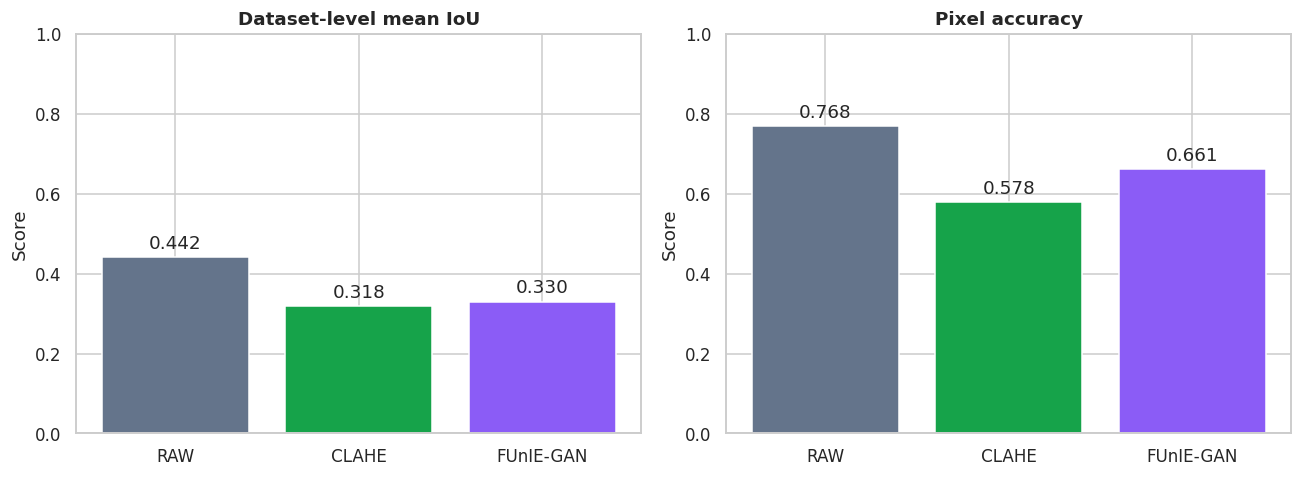

In [ ]:
def metrics_from_cm(cm):
    cm = np.asarray(cm,dtype=np.float64)
    tp = np.diag(cm)
    gt = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = gt+predicted-tp
    iou = np.divide(tp,union,out=np.full(NUM_CLASSES,np.nan),where=union>0)
    precision = np.divide(tp,predicted,out=np.zeros(NUM_CLASSES),where=predicted>0)
    recall = np.divide(tp,gt,out=np.zeros(NUM_CLASSES),where=gt>0)
    return {'miou':float(np.nanmean(iou)), 'pixel_accuracy':float(tp.sum()/cm.sum()),
            'iou':iou,'precision':precision,'recall':recall,'gt_pixels':gt,'predicted_pixels':predicted}

pooled = {method:cms[:,j].sum(axis=0) for j,method in enumerate(METHODS)}
results = {method:metrics_from_cm(cm) for method,cm in pooled.items()}
assert all((results[m]['gt_pixels']>0).all() for m in METHODS)
overall_df = pd.DataFrame([{'method':m,'miou':results[m]['miou'],
                            'pixel_accuracy':results[m]['pixel_accuracy']} for m in METHODS])
overall_df['delta_miou_vs_raw'] = overall_df['miou']-results['raw']['miou']
overall_df['delta_accuracy_vs_raw'] = overall_df['pixel_accuracy']-results['raw']['pixel_accuracy']
overall_df.to_csv(OUT/'overall_metrics.csv',index=False)
display(overall_df.style.format({c:'{:.4f}' for c in overall_df.columns if c!='method'}))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,title in zip(axes,['miou','pixel_accuracy'],['Dataset-level mean IoU','Pixel accuracy']):
    vals=[results[m][metric] for m in METHODS]
    bars=ax.bar([LABELS[m] for m in METHODS],vals,color=[COLORS[m] for m in METHODS])
    ax.set_ylim(0,1);ax.set_ylabel('Score');ax.set_title(title,fontweight='bold')
    ax.bar_label(bars,fmt='%.3f',padding=3)
fig.tight_layout();fig.savefig(FIG/'overall_performance.png',bbox_inches='tight');plt.show()

## 8. Per-Class IoU Analysis

The class-level results show that the overall declines were not confined to one category.

| Class | RAW IoU | CLAHE IoU | FUnIE-GAN IoU |
|---|---:|---:|---:|
| Water | 83.39% | 44.61% | 72.76% |
| Diver | 57.75% | 50.84% | 43.39% |
| Plant | 0.00% | 0.00% | 0.00% |
| Wreck | 41.82% | 30.96% | 24.76% |
| Robot | 11.53% | 0.38% | 3.69% |
| Reef | 56.61% | 51.38% | 44.51% |
| Fish | 46.15% | 43.39% | 34.71% |
| Sea-floor | 56.56% | 32.85% | 40.26% |

Neither enhancement method improved IoU for any of the eight classes. CLAHE's largest absolute decrease occurred for **water (−38.78 percentage points)**, followed by sea-floor (−23.71 pp). FUnIE-GAN reduced IoU most for wreck (−17.07 pp) and sea-floor (−16.29 pp). Plant remained at zero in all conditions, meaning that unchanged IoU in this category should not be mistaken for successful preservation of performance. The figure accompanying this section displays the class-specific differences in a directly comparable form.


method,clahe,funie_gan,raw,clahe_minus_raw,funie_gan_minus_raw
class,,,,,
water,0.4461,0.7276,0.8339,-0.3878,-0.1063
diver,0.5084,0.4339,0.5775,-0.0691,-0.1436
plant,0.0000,0.0000,0.0000,0.0000,0.0000
wreck,0.3096,0.2476,0.4182,-0.1087,-0.1707
robot,0.0038,0.0369,0.1153,-0.1115,-0.0784
reef,0.5138,0.4451,0.5661,-0.0523,-0.1210
fish,0.4339,0.3471,0.4615,-0.0276,-0.1144
sea-floor,0.3285,0.4026,0.5656,-0.2371,-0.1629


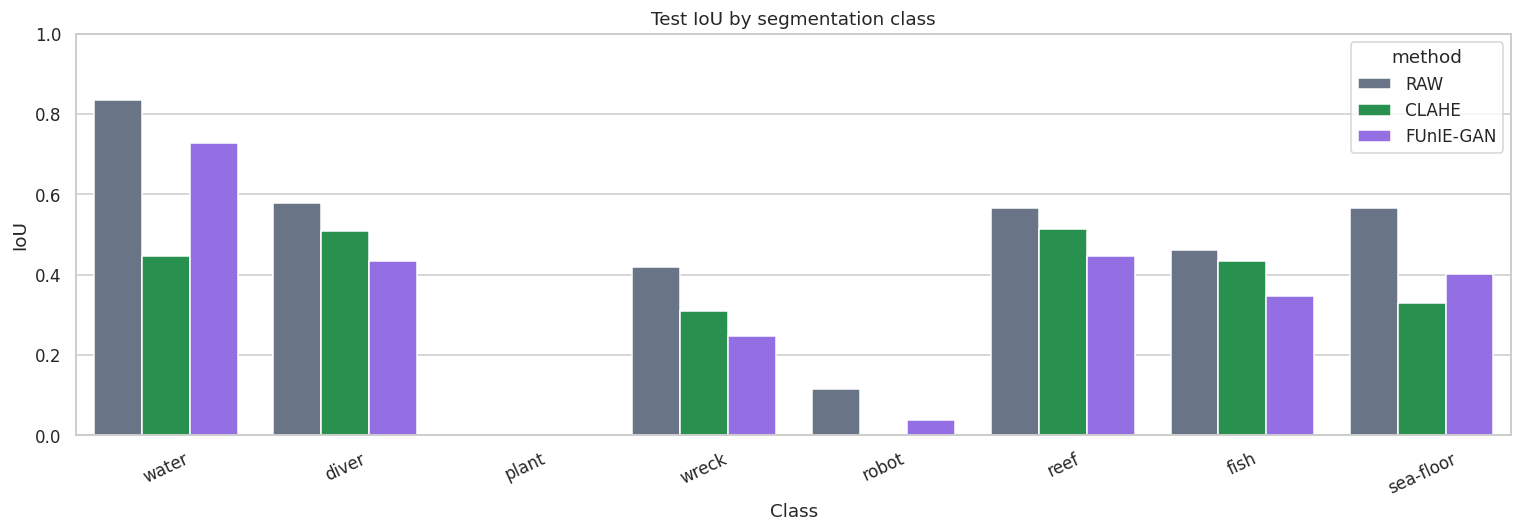

In [ ]:
class_rows=[]
for m in METHODS:
    r=results[m]
    for k,name in enumerate(CLASS_NAMES):
        class_rows.append({'method':m,'class':name,'iou':r['iou'][k],
                           'precision':r['precision'][k],'recall':r['recall'][k],
                           'gt_pixels':int(r['gt_pixels'][k]),'predicted_pixels':int(r['predicted_pixels'][k])})
class_df=pd.DataFrame(class_rows)
class_df.to_csv(OUT/'per_class_metrics.csv',index=False)
pivot=class_df.pivot(index='class',columns='method',values='iou').reindex(CLASS_NAMES)
for m in ['clahe','funie_gan']: pivot[f'{m}_minus_raw']=pivot[m]-pivot['raw']
display(pivot.style.format('{:.4f}'))
pivot.to_csv(OUT/'per_class_iou_comparison.csv')
plot_df=class_df.copy();plot_df['method']=plot_df['method'].map(LABELS)
fig,ax=plt.subplots(figsize=(14,5))
sns.barplot(data=plot_df,x='class',y='iou',hue='method',palette={LABELS[m]:COLORS[m] for m in METHODS},ax=ax)
ax.set(title='Test IoU by segmentation class',xlabel='Class',ylabel='IoU',ylim=(0,1))
ax.tick_params(axis='x',rotation=25);fig.tight_layout()
fig.savefig(FIG/'per_class_iou.png',bbox_inches='tight');plt.show()

## 9. Plant and Robot Segmentation Diagnostics

Plant and robot were the primary classes of interest because the baseline model had difficulty recognizing them in Notebook 02. On the official test set, the **plant class contained 259,185 ground-truth pixels**, yet the U-Net predicted **zero plant pixels** under all three input conditions. Plant precision, recall, and IoU therefore remained at zero. Enhancement did not resolve this complete prediction failure.

For **robot**, the test masks contained **45,682 ground-truth pixels**. RAW achieved **11.53% IoU**, **54.01% precision**, and **12.78% recall**, with 10,812 predicted robot pixels. CLAHE reduced robot IoU to **0.38%** and recall to **0.39%**, with only 636 predicted robot pixels. FUnIE-GAN achieved **3.69% IoU** and **3.91% recall**, with 4,584 predicted robot pixels. Thus, both methods substantially reduced robot detection, particularly CLAHE.

The confusion analysis further indicates that plant pixels were primarily assigned to reef: **68.87%** under RAW, **79.29%** under CLAHE, and **84.16%** under FUnIE-GAN. These results suggest that enhancement did not make the learned representation more discriminative for vegetation. For robot pixels, the dominant errors varied by method, but neither enhanced condition recovered the RAW baseline's robot recall. These observations concern model predictions; they do not by themselves prove the underlying visual cause of each error.


,method,class,iou,precision,recall,gt_pixels,predicted_pixels
10,clahe,plant,0.0000,0.0000,0.0000,259185,0
18,funie_gan,plant,0.0000,0.0000,0.0000,259185,0
2,raw,plant,0.0000,0.0000,0.0000,259185,0
12,clahe,robot,0.0038,0.2767,0.0039,45682,636
20,funie_gan,robot,0.0369,0.3901,0.0391,45682,4584
4,raw,robot,0.1153,0.5401,0.1278,45682,10812


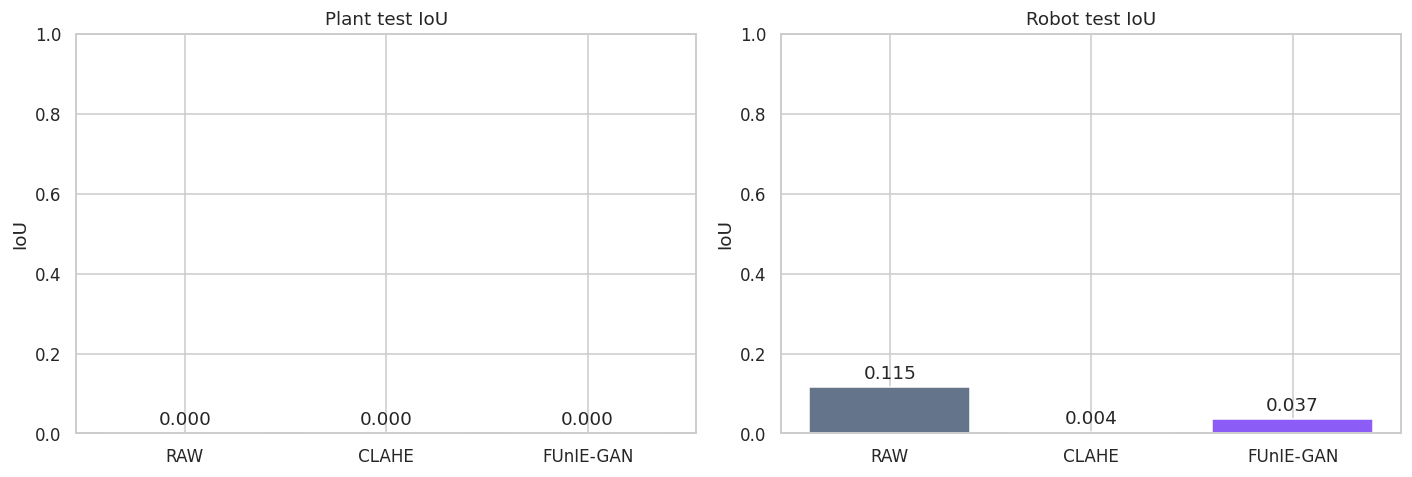

,raw,clahe,funie_gan
water,6.58%,0.76%,1.78%
diver,0.00%,0.02%,0.05%
plant,0.00%,0.00%,0.00%
wreck,19.50%,9.69%,9.35%
robot,0.01%,0.00%,0.00%
reef,68.87%,79.29%,84.16%
fish,2.29%,3.72%,2.74%
sea-floor,2.75%,6.51%,1.91%


,raw,clahe,funie_gan
water,18.88%,12.88%,21.82%
diver,56.25%,67.35%,25.61%
plant,0.00%,0.00%,0.00%
wreck,0.27%,4.74%,1.02%
robot,12.78%,0.39%,3.91%
reef,1.64%,2.18%,8.34%
fish,10.10%,10.74%,38.92%
sea-floor,0.08%,1.72%,0.39%


In [ ]:
targets=class_df[class_df['class'].isin(['plant','robot'])].copy()
display(targets.sort_values(['class','method']).style.format({'iou':'{:.4f}','precision':'{:.4f}','recall':'{:.4f}'}))
targets.to_csv(OUT/'plant_robot_diagnostics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,name in zip(axes,['plant','robot']):
    subset=targets[targets['class']==name]
    bars=ax.bar([LABELS[m] for m in subset['method']],subset['iou'],color=[COLORS[m] for m in subset['method']])
    ax.set(title=f'{name.title()} test IoU',ylabel='IoU',ylim=(0,1))
    ax.bar_label(bars,fmt='%.3f',padding=3)
fig.tight_layout();fig.savefig(FIG/'plant_robot_iou.png',bbox_inches='tight');plt.show()
for name in ['plant','robot']:
    k=CLASS_NAMES.index(name)
    confusion=pd.DataFrame({m:pooled[m][k]/max(pooled[m][k].sum(),1) for m in METHODS},index=CLASS_NAMES)
    confusion.to_csv(OUT/f'{name}_gt_prediction_distribution.csv')
    display(confusion.style.format('{:.2%}').set_caption(f'Predictions for ground-truth {name} pixels'))

## 10. Qualitative Segmentation Comparisons

The comparison figure presents matched RAW, CLAHE, and FUnIE-GAN images alongside the original ground truth and the three predicted segmentation masks. I used predetermined, evenly spaced test examples to avoid choosing only favorable outcomes. This visualization provides a qualitative counterpart to the aggregate metrics: the same scene can yield substantially different predictions after image enhancement even though the network and annotations are unchanged.

The quantitative findings provide the appropriate context for interpreting these examples. The RAW condition has the highest overall test mIoU, while both enhanced conditions lose accuracy across multiple classes. Individual scenes may still exhibit local improvements or visually appealing enhancement; such examples should not be generalized into an overall performance claim. The next section separately examines the largest image-level improvements and regressions.


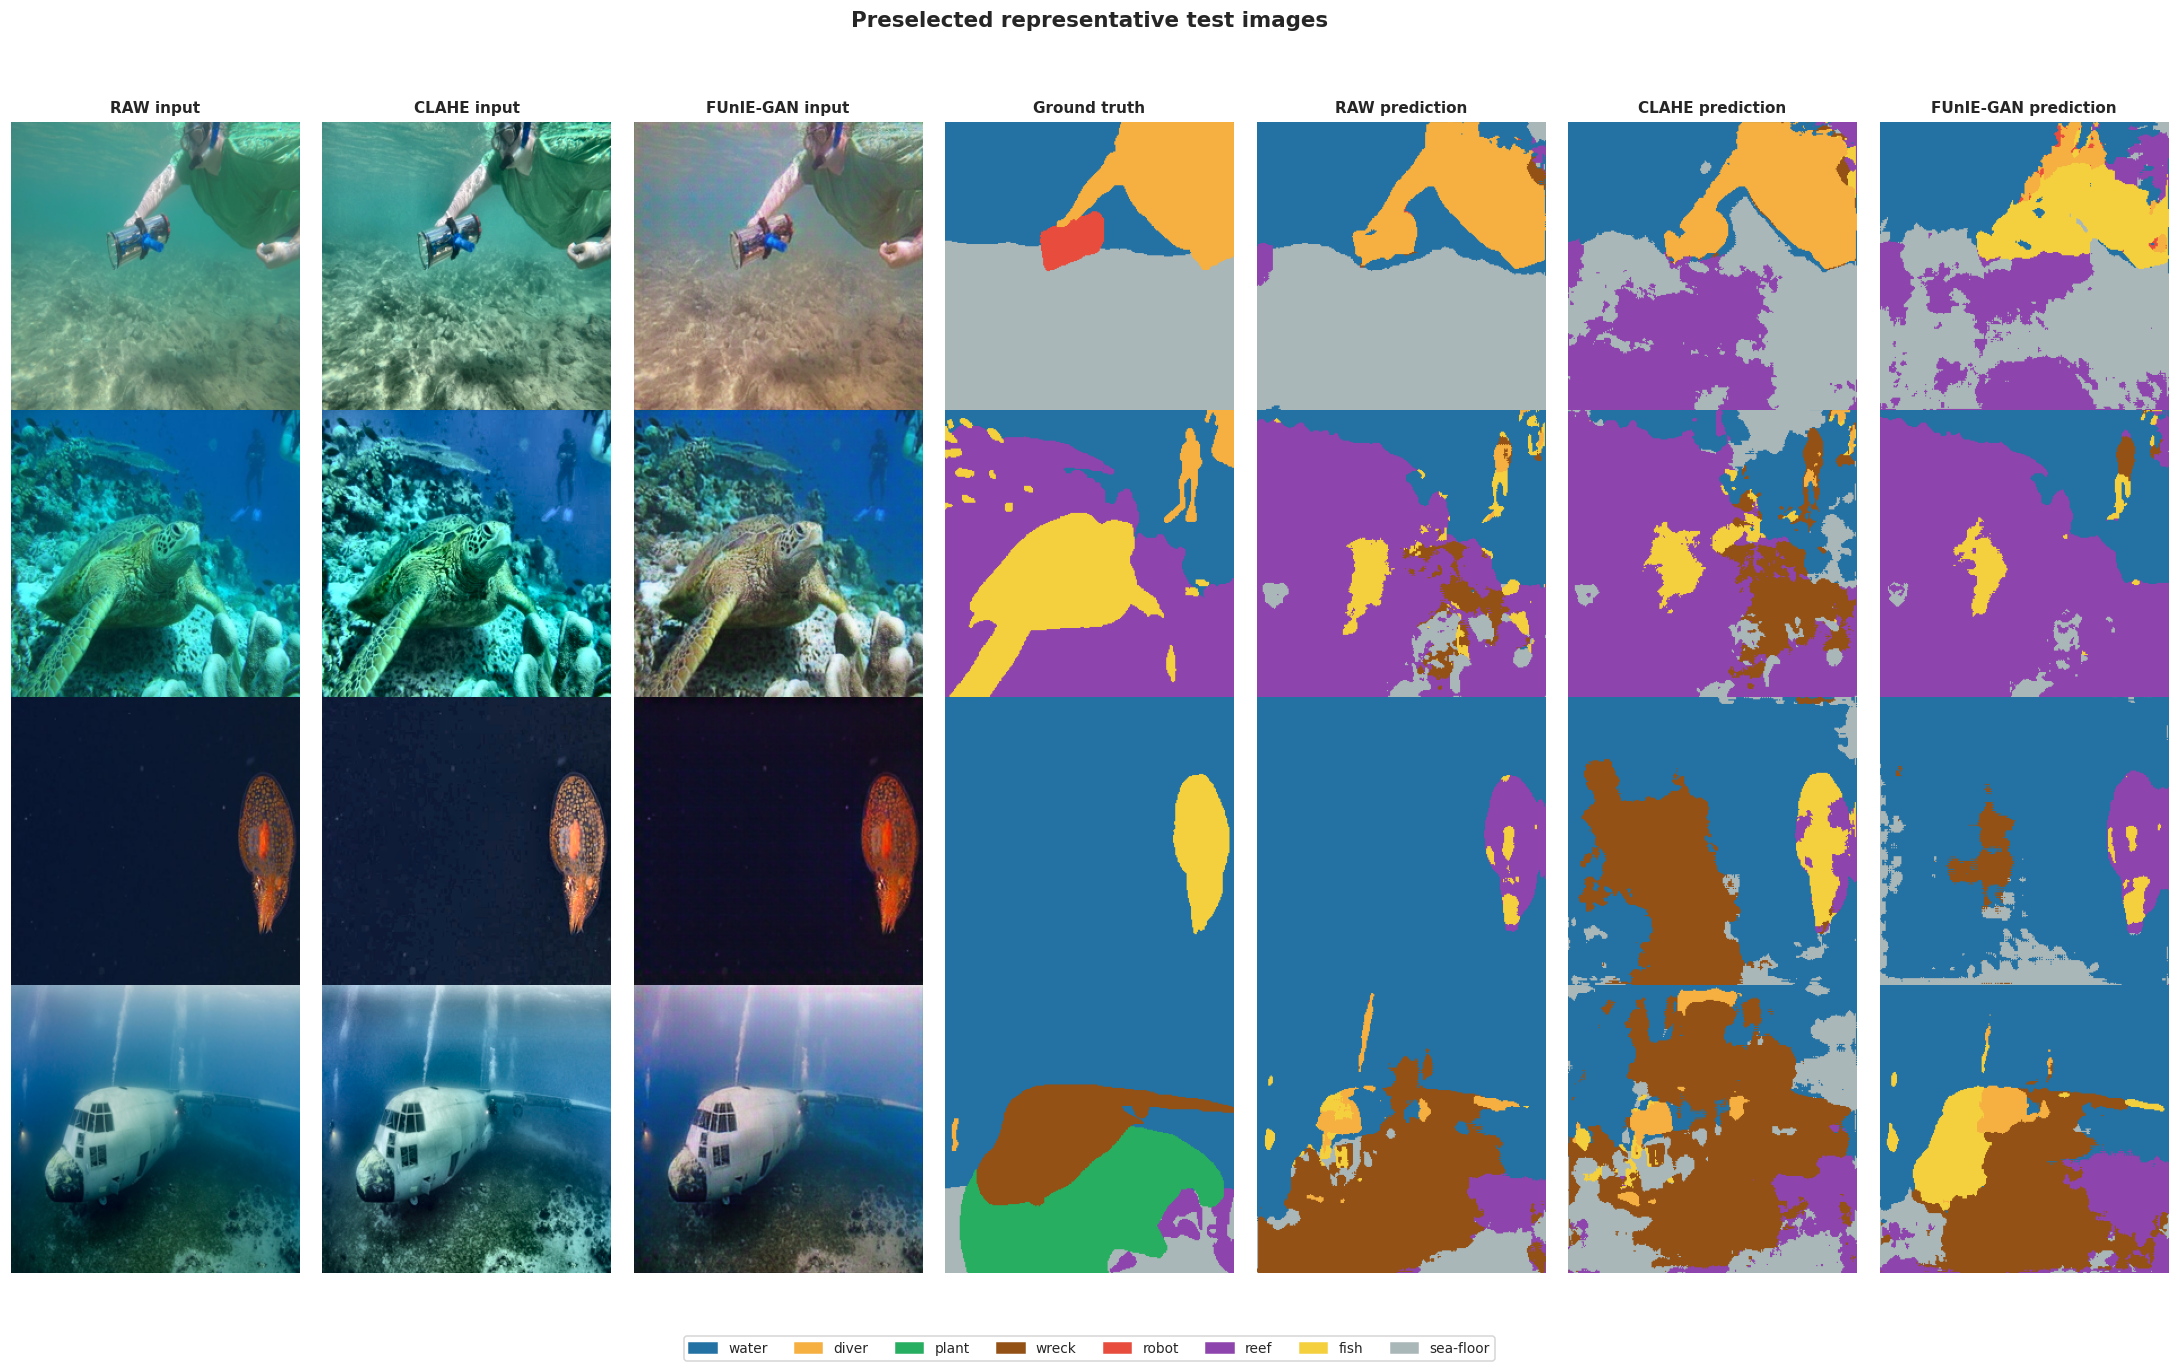

In [ ]:
palette=np.array(['#2471A3','#F5B041','#27AE60','#935116','#E74C3C','#8E44AD','#F4D03F','#AAB7B8'])
from matplotlib.colors import to_rgb
mask_colors=np.uint8(np.array([to_rgb(c) for c in palette])*255)

def color_mask(mask): return mask_colors[np.asarray(mask,dtype=np.int64)]

def read_prediction(stem,method):
    with Image.open(PRED/method/f'{stem}.png') as im: return np.asarray(im).copy()

def show_triplet(indices,filename,title):
    fig,axes=plt.subplots(len(indices),7,figsize=(20,3.1*len(indices)),squeeze=False)
    headers=['RAW input','CLAHE input','FUnIE-GAN input','Ground truth','RAW prediction','CLAHE prediction','FUnIE-GAN prediction']
    for row,i in enumerate(indices):
        stem=STEMS[i];gt=test_ds[i][1].numpy()
        images=[input_rgb(stem,m,i) for m in METHODS]+[color_mask(gt)]+[color_mask(read_prediction(stem,m)) for m in METHODS]
        for col,img in enumerate(images):
            axes[row,col].imshow(img);axes[row,col].axis('off')
            if row==0: axes[row,col].set_title(headers[col],fontsize=10,fontweight='bold')
        axes[row,0].set_ylabel(stem,fontsize=9)
    fig.suptitle(title,fontsize=14,fontweight='bold')
    fig.legend(handles=[Patch(color=palette[k],label=name) for k,name in enumerate(CLASS_NAMES)],
               loc='lower center',ncol=8,bbox_to_anchor=(0.5,-0.015),fontsize=9)
    fig.tight_layout(rect=(0,0.04,1,0.95))
    fig.savefig(FIG/filename,bbox_inches='tight');plt.show()

representative_indices=np.linspace(0,len(STEMS)-1,4,dtype=int).tolist()
show_triplet(representative_indices,'representative_segmentation_examples.png','Preselected representative test images')

## 11. Error Analysis and Image-Level Changes

I examined row-normalized confusion matrices, where each row represents a ground-truth class and each column represents a predicted class. This normalization distinguishes class-specific prediction behavior from differences in class frequency. I also ranked paired test images by their segmentation change relative to RAW, retaining both the largest improvements and the largest regressions rather than selecting examples only for visual impact.

The confusion patterns support the broader performance results. Plant predictions remained absent, and enhanced inputs increased the share of plant pixels assigned to reef. Robot recall fell from **12.78% under RAW** to **0.39% with CLAHE** and **3.91% with FUnIE-GAN**. At the same time, the overall class-level IoU table shows reductions in every category under both enhancement methods. The ranked examples illustrate variability between scenes, but they do not overturn the aggregate finding that enhancement degraded this frozen model's test performance.


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(19,5.2))
for ax,m in zip(axes,METHODS):
    cm=pooled[m].astype(float)
    norm=np.divide(cm,cm.sum(axis=1,keepdims=True),out=np.zeros_like(cm),where=cm.sum(axis=1,keepdims=True)>0)
    sns.heatmap(norm,cmap='Blues',vmin=0,vmax=1,xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
    ax.set(title=f'{LABELS[m]} confusion',xlabel='Predicted',ylabel='Ground truth')
    ax.tick_params(axis='x',rotation=45)
    pd.DataFrame(pooled[m],index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUT/f'confusion_counts_{m}.csv')
fig.tight_layout();fig.savefig(FIG/'confusion_matrices.png',bbox_inches='tight');plt.show()
image_rows=[]
for i,stem in enumerate(STEMS):
    for j,m in enumerate(METHODS):
        r=metrics_from_cm(cms[i,j])
        image_rows.append({'stem':stem,'method':m,'image_miou':r['miou'],'image_pixel_accuracy':r['pixel_accuracy']})
image_df=pd.DataFrame(image_rows)
image_df.to_csv(OUT/'per_image_metrics.csv',index=False)
wide=image_df.pivot(index='stem',columns='method',values='image_miou').reindex(STEMS)
for m in ['clahe','funie_gan']: wide[f'{m}_delta']=wide[m]-wide['raw']
wide.to_csv(OUT/'paired_per_image_iou.csv')
for m in ['clahe','funie_gan']:
    ranked=wide[f'{m}_delta'].sort_values()
    print(f'{LABELS[m]} | largest regressions:');display(ranked.head(3).to_frame('delta_image_mIoU'))
    print(f'{LABELS[m]} | largest improvements:');display(ranked.tail(3).iloc[::-1].to_frame('delta_image_mIoU'))
    chosen=list(dict.fromkeys([STEMS.index(s) for s in list(ranked.head(2).index)+list(ranked.tail(2).iloc[::-1].index)]))
    show_triplet(chosen,f'{m}_largest_changes.png',f'{LABELS[m]}: largest per-image mIoU regressions and improvements (post hoc)')

Output hidden; open in https://colab.research.google.com to view.

## 12. Paired Bootstrap Uncertainty Analysis

To characterize uncertainty in the observed differences, I used **2,000 paired bootstrap resamples** of the 110 test images (seed 42). Each resample retained the RAW, CLAHE, and FUnIE-GAN observations for the same selected image identities. I recomputed pooled-count metrics and obtained percentile-based **95% confidence intervals** for the enhanced-minus-RAW differences.

| Comparison | Metric | Observed difference | 95% bootstrap interval |
|---|---|---:|---:|
| CLAHE − RAW | mIoU | −12.42 pp | [−14.67, −10.16] pp |
| FUnIE-GAN − RAW | mIoU | −11.22 pp | [−13.70, −8.60] pp |
| CLAHE − RAW | Pixel accuracy | −19.01 pp | [−22.76, −15.41] pp |
| FUnIE-GAN − RAW | Pixel accuracy | −10.71 pp | [−13.47, −8.03] pp |
| CLAHE − RAW | Robot IoU | −11.15 pp | [−17.77, −3.47] pp |
| FUnIE-GAN − RAW | Robot IoU | −7.84 pp | [−14.95, −1.74] pp |

All reported intervals for overall mIoU, pixel accuracy, and robot IoU lie below zero. This supports the conclusion that the negative differences are not driven solely by a small number of particular sampled test images, under the image-level resampling assumptions. Plant IoU differences and intervals were exactly zero because all three conditions failed to predict the plant class. These intervals quantify uncertainty **within this test sample and resampling design**; they do not prove generalization to different underwater datasets or deployed robots.


,method,metric,observed_delta,ci_lower,ci_upper,valid_replicates
0,clahe,miou,-0.1242,-0.1467,-0.1016,2000
1,clahe,pixel_accuracy,-0.1901,-0.2276,-0.1541,2000
2,clahe,plant_iou,+0.0000,+0.0000,+0.0000,2000
3,clahe,robot_iou,-0.1115,-0.1777,-0.0347,2000
4,funie_gan,miou,-0.1122,-0.1370,-0.0860,2000
5,funie_gan,pixel_accuracy,-0.1071,-0.1347,-0.0803,2000
6,funie_gan,plant_iou,+0.0000,+0.0000,+0.0000,2000
7,funie_gan,robot_iou,-0.0784,-0.1495,-0.0174,2000


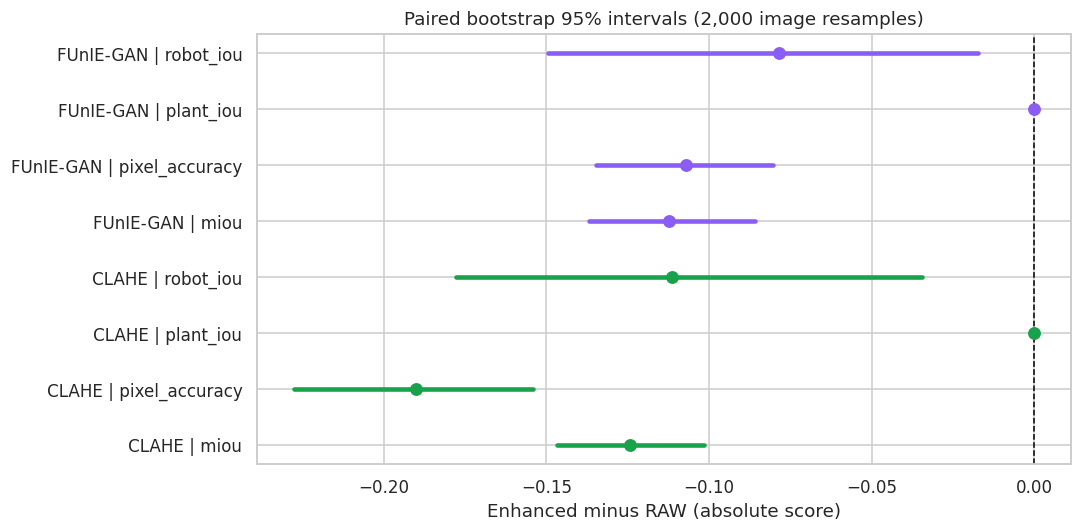

In [ ]:
BOOTSTRAP_REPS=2000
rng=np.random.default_rng(SEED)
boot_rows=[]
for rep in range(BOOTSTRAP_REPS):
    indices=rng.integers(0,len(STEMS),size=len(STEMS))
    base=metrics_from_cm(cms[indices,0].sum(axis=0))
    for j,m in enumerate(METHODS[1:],start=1):
        enhanced=metrics_from_cm(cms[indices,j].sum(axis=0))
        boot_rows.append({'replicate':rep,'method':m,
                          'delta_miou':enhanced['miou']-base['miou'],
                          'delta_pixel_accuracy':enhanced['pixel_accuracy']-base['pixel_accuracy'],
                          'delta_plant_iou':enhanced['iou'][CLASS_NAMES.index('plant')]-base['iou'][CLASS_NAMES.index('plant')],
                          'delta_robot_iou':enhanced['iou'][CLASS_NAMES.index('robot')]-base['iou'][CLASS_NAMES.index('robot')]})
boot_df=pd.DataFrame(boot_rows)
boot_df.to_csv(OUT/'paired_bootstrap_replicates.csv',index=False)
summary_rows=[]
for m in METHODS[1:]:
    for metric in ['miou','pixel_accuracy','plant_iou','robot_iou']:
        field='delta_'+metric
        if metric in ['miou','pixel_accuracy']:
            observed=results[m][metric]-results['raw'][metric]
        else:
            k=CLASS_NAMES.index(metric.split('_')[0])
            observed=results[m]['iou'][k]-results['raw']['iou'][k]
        samples=boot_df.loc[boot_df.method==m,field].dropna().to_numpy()
        assert len(samples)>0
        lo,hi=np.percentile(samples,[2.5,97.5])
        summary_rows.append({'method':m,'metric':metric,'observed_delta':observed,
                             'ci_lower':lo,'ci_upper':hi,'valid_replicates':len(samples)})
ci_df=pd.DataFrame(summary_rows)
ci_df.to_csv(OUT/'paired_bootstrap_95ci.csv',index=False)
display(ci_df.style.format({'observed_delta':'{:+.4f}','ci_lower':'{:+.4f}','ci_upper':'{:+.4f}'}))
fig,ax=plt.subplots(figsize=(10,5))
for y,row in enumerate(ci_df.itertuples(index=False)):
    ax.plot([row.ci_lower,row.ci_upper],[y,y],color=COLORS[row.method],lw=3)
    ax.scatter(row.observed_delta,y,color=COLORS[row.method],s=55,zorder=3)
ax.axvline(0,color='black',ls='--',lw=1)
ax.set_yticks(range(len(ci_df)),[f'{LABELS[r.method]} | {r.metric}' for r in ci_df.itertuples(index=False)])
ax.set(xlabel='Enhanced minus RAW (absolute score)',title='Paired bootstrap 95% intervals (2,000 image resamples)')
fig.tight_layout();fig.savefig(FIG/'paired_bootstrap_intervals.png',bbox_inches='tight');plt.show()

## 13. Computational Efficiency and Enhancement Overhead

I measured segmentation inference latency for each condition and combined those observations descriptively with the enhancement processing times recorded in Notebook 03. Median segmentation inference times were similar: **5.341 ms for RAW**, **5.307 ms for CLAHE**, and **5.294 ms for FUnIE-GAN**. The RAW **mean of 33.171 ms** was strongly affected by an outlier (maximum **3,053.225 ms**), whereas CLAHE and FUnIE-GAN mean inference times were **5.450 ms** and **5.576 ms**, respectively. Median values are therefore more representative of typical segmentation-only latency in this run.

Previously measured mean enhancement overhead was **2.177 ms for CLAHE** and **9.021 ms for FUnIE-GAN**. Adding these separate mean measurements yields indicative sequential costs of approximately **7.627 ms** and **14.598 ms**, respectively, for enhancement plus segmentation. These sums are not end-to-end measurements on a deployed robotic platform, and they should not be compared naively with the outlier-inflated RAW mean. Since neither enhancement improved segmentation accuracy, the additional preprocessing cost offers no demonstrated accuracy benefit in this fixed-model experiment.


,method,mean,median,std,min,max
0,clahe,5.450,5.307,0.463,5.125,7.803
1,funie_gan,5.576,5.294,0.947,5.128,13.062
2,raw,33.171,5.341,290.593,5.133,3053.225


,method,mean,median,enhancement_mean_ms,enhancement_median_ms,indicative_sequential_mean_ms
0,clahe,5.450,5.307,2.177,2.069,7.627
1,funie_gan,5.576,5.294,9.021,8.954,14.598
2,raw,33.171,5.341,0.000,NaN,33.171


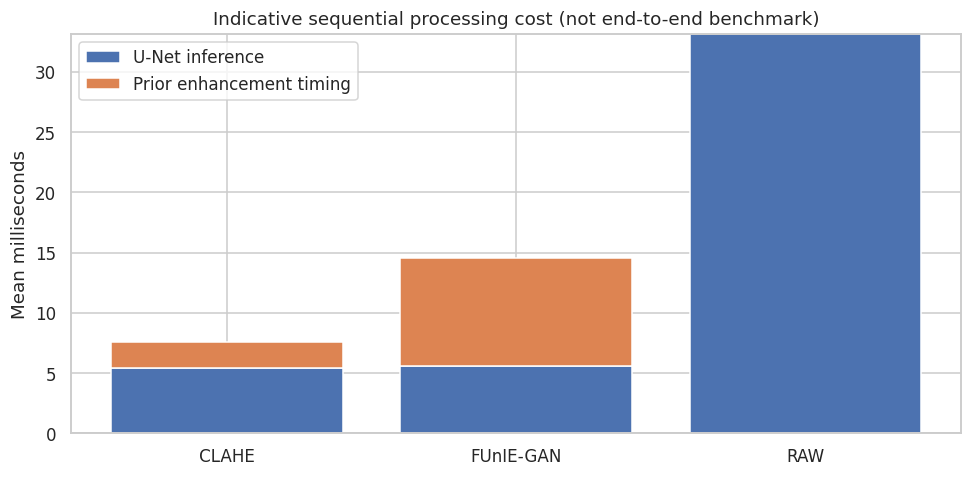

In [ ]:
timing_summary=inference_df.groupby('method')['inference_ms'].agg(['mean','median','std','min','max']).reset_index()
timing_summary.to_csv(OUT/'segmentation_inference_timing.csv',index=False)
display(timing_summary.round(3))
quality_timing=NB03/'enhancement_manifest.csv'
prior=pd.read_csv(quality_timing)
assert {'split','method','processing_ms'}.issubset(prior.columns)
prior_test=prior.loc[prior['split']=='test']
overhead=prior_test.groupby('method')['processing_ms'].agg(['mean','median']).reset_index()
overhead=overhead.rename(columns={'mean':'enhancement_mean_ms','median':'enhancement_median_ms'})
combined=timing_summary[['method','mean','median']].merge(overhead,on='method',how='left')
combined['enhancement_mean_ms']=combined['enhancement_mean_ms'].fillna(0)
combined['indicative_sequential_mean_ms']=combined['mean']+combined['enhancement_mean_ms']
combined.to_csv(OUT/'indicative_pipeline_timing.csv',index=False)
display(combined.round(3))
fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar([LABELS[m] for m in combined.method],combined['mean'],label='U-Net inference')
ax.bar([LABELS[m] for m in combined.method],combined['enhancement_mean_ms'],bottom=combined['mean'],label='Prior enhancement timing')
ax.set(title='Indicative sequential processing cost (not end-to-end benchmark)',ylabel='Mean milliseconds')
ax.legend();fig.tight_layout();fig.savefig(FIG/'indicative_processing_cost.png',bbox_inches='tight');plt.show()

## 14. Output Verification and Reproducibility Audit

The final audit passed. I verified **330 saved prediction masks**, **110 matched image triplets**, and unchanged ground-truth class counts. The experiment saved its tables to `results/tables/notebook_04`, figures to `results/figures/notebook_04`, and prediction masks to `results/predictions/notebook_04` within `Underwater_Research`. The evaluation records preserve the matched test identities, metrics, bootstrap comparisons, and checkpoint information required for subsequent review.

These checks support reproducibility of the recorded comparison, although independent reproduction would still require the archived source files, original dataset, pretrained enhancement outputs, checkpoint, and compatible execution environment.


In [ ]:
assert cms.shape == (110,3,8,8)
assert len(inference_df)==330 and not inference_df.duplicated(['stem','method']).any()
assert set(inference_df['stem'])==set(STEMS)
assert set(inference_df['method'])==set(METHODS)
for row in inference_df.itertuples(index=False):
    path=Path(row.prediction_path)
    assert path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest()==row.prediction_sha256
    with Image.open(path) as im:
        a=np.asarray(im)
    assert a.shape==(256,256) and a.min()>=0 and a.max()<NUM_CLASSES
assert np.array_equal(cms.sum(axis=0)[0].sum(axis=1),cms.sum(axis=0)[1].sum(axis=1))
assert np.array_equal(cms.sum(axis=0)[0].sum(axis=1),cms.sum(axis=0)[2].sum(axis=1))
assert np.array_equal(cms.sum(axis=(0,2,3)),np.full(3,110*256*256))
config={'seed':SEED,'manifest_sha256':manifest_sha,'checkpoint_path':str(CHECKPOINT),
        'checkpoint_sha256':checkpoint_sha,'checkpoint_best_epoch':112,
        'enhancement_config_sha256':hashlib.sha256(config_path.read_bytes()).hexdigest(),
        'enhancement_manifest_sha256':hashlib.sha256(enhancement_manifest_path.read_bytes()).hexdigest(),
        'test_images':110,'methods':METHODS,'normalization':'RGB uint8 / 127.5 - 1',
        'bootstrap_replicates':BOOTSTRAP_REPS,'bootstrap_unit':'paired image stem',
        'ci_method':'percentile 2.5 / 97.5','device':str(DEVICE),
        'test_set_policy':'evaluation only; no tuning','model_policy':'frozen RAW-trained U-Net'}
(OUT/'evaluation_config.json').write_text(json.dumps(config,indent=2))
print('Audit passed: 330 prediction masks; 110 matched triplets; unchanged GT counts.')
print('Evaluation records:',OUT)
print('Figures:',FIG)
print('Prediction masks:',PRED)
print('Actual test metrics (not validation):')
display(overall_df.round(4))

Audit passed: 330 prediction masks; 110 matched triplets; unchanged GT counts.
Evaluation records: /content/drive/MyDrive/Underwater_Research/results/tables/notebook_04
Figures: /content/drive/MyDrive/Underwater_Research/results/figures/notebook_04
Prediction masks: /content/drive/MyDrive/Underwater_Research/results/predictions/notebook_04
Actual test metrics (not validation):


,method,miou,pixel_accuracy,delta_miou_vs_raw,delta_accuracy_vs_raw
0,raw,0.4423,0.7683,0.0000,0.0000
1,clahe,0.3180,0.5783,-0.1242,-0.1901
2,funie_gan,0.3301,0.6612,-0.1122,-0.1071


## 15. Discussion, Conclusion, and Handoff to Notebook 05

### 15.1 Interpretation of the Main Finding

The controlled experiment found that **inference-time underwater image enhancement reduced segmentation performance when the model was trained only on RAW imagery**. RAW achieved **44.23% test mIoU**, compared with **31.80% for CLAHE** and **33.01% for FUnIE-GAN**. Pixel accuracy similarly decreased from **76.83%** to **57.83%** and **66.12%**, respectively. The paired bootstrap intervals for both mIoU differences excluded zero, reinforcing the consistency of the observed reductions across resampled test images.

This finding is compatible with an input-distribution mismatch: the U-Net learned features from RAW images, while enhancement altered luminance, contrast, color, and texture characteristics. However, this experiment did **not directly measure feature-distribution shift inside the network**, so I treat that explanation as a plausible mechanism rather than an established causal diagnosis.

### 15.2 Implications for Challenging Classes

Neither enhancement method improved IoU for any of the eight SUIM classes. The plant class remained completely unrecognized under all conditions, despite containing **259,185 annotated test pixels**. Robot IoU decreased from **11.53% under RAW** to **0.38% with CLAHE** and **3.69% with FUnIE-GAN**. The robot recall reductions were particularly severe, indicating that the enhanced inputs led the unchanged model to identify substantially fewer true robot pixels. The plant-to-reef confusion pattern also worsened under enhancement.

These outcomes demonstrate that image-level contrast or clipping changes observed in Notebook 03 did not translate into improved segmentation of the most difficult target categories. In this experiment, visually altered inputs were less compatible with the features learned by the baseline model.

### 15.3 Practical and Methodological Implications

The computational comparison also weighs against inserting either enhancement method before this particular frozen U-Net. CLAHE and FUnIE-GAN added preprocessing time without improving test accuracy. This does not rule out enhancement as a useful preprocessing strategy in general. A model trained or fine-tuned on consistently enhanced images, or a joint enhancement-segmentation system, might respond differently. Such systems would require separate training protocols and validation-based model selection to support a fair comparison.

The present study deliberately isolates **test-time input transformation**. It therefore supports a narrow but important conclusion: an enhancement technique should not be adopted for robotic segmentation solely because it improves visual appearance or low-level image statistics.

### 15.4 Limitations

The evaluation used one SUIM test partition of **110 images**, one frozen U-Net architecture and checkpoint, and two fixed enhancement methods. The paired bootstrap intervals quantify variation under image resampling, not uncertainty across new datasets, training runs, or underwater operating environments. Image-level bootstrap observations may also be dependent if scenes share acquisition conditions. The latency measurements came from a Colab environment rather than onboard robotic hardware, and the separate enhancement-plus-inference estimates were not direct end-to-end benchmarks. Finally, the experiment cannot determine whether retraining on enhanced imagery would recover or surpass RAW performance.

### 15.5 Conclusion and Research Handoff

I conclude that **CLAHE and FUnIE-GAN did not improve CNN-based underwater semantic segmentation in the tested frozen-model setting**. Both decreased overall mIoU and pixel accuracy; both worsened robot segmentation; and neither corrected the complete failure to predict plant pixels. The evidence illustrates why image-quality enhancement and task-level perception quality must be evaluated separately.

Notebook 05 will synthesize the dataset preparation, baseline training, enhancement characterization, and controlled segmentation results. Its final discussion will distinguish observed findings from proposed explanations, consider implications for underwater robotic perception, and identify carefully scoped future research directions.
